In [30]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base_dir = Path.cwd().resolve()
csv_file = base_dir / "superstore.csv"
print('csv_file_path: ',csv_file)

csv_file_path:  /Users/ethanauyeung/data_analyst/superstore_data_analysis_project_python/superstore.csv


In [56]:
# GLOBAL SETTINGS
pd.set_option("display.max_columns", None)   # show every column when printing
pd.set_option("display.width", 160)

DATA_PATH = r"C:\Users\ANMOL\Desktop\Jupyyy\Sample - Superstore.csv"
IMAGES_DIR = "images"
os.makedirs(IMAGES_DIR, exist_ok=True)

# A consistent, pleasant color palette used across all charts
PALETTE = ["#2E86AB", "#F26419", "#33A02C", "#E63946", "#8E44AD",
           "#F4A261", "#118AB2", "#6A994E", "#EF476F", "#264653"]

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 10
def section(title):
    """Small helper to print a readable section header in the console output."""
    line = "=" * 78
    print(f"\n{line}\n{title}\n{line}")


def insight(text):
    """Small helper to consistently format a business insight line."""
    print(f"  Insight -> {text}")


def savefig(fig, name):
    """Save a matplotlib figure to the images/ folder and close it to free memory."""
    path = os.path.join(IMAGES_DIR, name)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    print(f"  [Saved chart] {path}")

In [33]:
# ===============================================================================
# 1. load data
# ===============================================================================
try:
    df = pd.read_csv(csv_file, encoding='latin-1')
    print("success: latin-1")
except UnicodeDecodeError:
    print("latin-1 failed")
df.head()

success: latin-1


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [34]:
# ===============================================================================
# 2.data exploration
# ===============================================================================

print("\n--- first 5 rows ---")
print(df.head())

print("\n--- last 5 rows ---")
print(df.tail())

print("\n--- shape(rows, columns)")
print(df.shape)

print("\n--- cloumns names ---")
print(df.columns)




--- first 5 rows ---
   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  

In [35]:
print("\n--- data types ---")
print(df.dtypes)



--- data types ---
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object


In [36]:
print("\n--- missing values per column ")
print(df.isnull().sum())


--- missing values per column 
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [37]:
print("\n--- duplicate rows ---")
print(f"Number of exact dumplicate rows: {df.duplicated().sum()}")


--- duplicate rows ---
Number of exact dumplicate rows: 0


In [38]:
print("\n--- descriptive statistics (numeric columns) ---")
print(df.describe())


--- descriptive statistics (numeric columns) ---
            Row ID   Postal Code         Sales     Quantity     Discount  \
count  9994.000000   9994.000000   9994.000000  9994.000000  9994.000000   
mean   4997.500000  55190.379428    229.858001     3.789574     0.156203   
std    2885.163629  32063.693350    623.245101     2.225110     0.206452   
min       1.000000   1040.000000      0.444000     1.000000     0.000000   
25%    2499.250000  23223.000000     17.280000     2.000000     0.000000   
50%    4997.500000  56430.500000     54.490000     3.000000     0.200000   
75%    7495.750000  90008.000000    209.940000     5.000000     0.200000   
max    9994.000000  99301.000000  22638.480000    14.000000     0.800000   

            Profit  
count  9994.000000  
mean     28.656896  
std     234.260108  
min   -6599.978000  
25%       1.728750  
50%       8.666500  
75%      29.364000  
max    8399.976000  


In [39]:
print("\n--- Descriptive statistics (categorical columns) ---")
categorical_cols = df.select_dtypes(include=["object", "string"]).columns
print(categorical_cols)
print(df[categorical_cols].describe())


--- Descriptive statistics (categorical columns) ---
Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Region',
       'Product ID', 'Category', 'Sub-Category', 'Product Name'],
      dtype='object')
              Order ID Order Date   Ship Date       Ship Mode Customer ID  \
count             9994       9994        9994            9994        9994   
unique            5009       1237        1334               4         793   
top     CA-2017-100111   9/5/2016  12/16/2015  Standard Class    WB-21850   
freq                14         38          35            5968          37   

        Customer Name   Segment        Country           City       State  \
count            9994      9994           9994           9994        9994   
unique            793         3              1            531          49   
top     William Brown  Consumer  United States  New York City  California   
freq             

In [40]:
# handle missing values
missing_before = df.isnull().sum().sum()
if missing_before > 0:
    numeric_cols = df.select_dtypes(include = np.number).columns
    for col in numeric_cols:
        if df[col].isnull().any():
            df[col] = df[col].fillna(df[col].median())
    cate_cols = df.select_dtypes(include="object").columns
    for col in cate_cols:
        if df[col].isnull().any():
            df[col] = df[col].fillna(df[col].mode()[0])
    print(f"Filled {missing_before} missing values (numeric -> median, categorical -> mode).")
else:
    print("No missing values found. Dataset is already clean on this front.")

No missing values found. Dataset is already clean on this front.


In [41]:
# remove duplicate rows
dupes_before = df.duplicated().sum()
if dupes_before > 0:
    df = df.drop_duplicates()
    print(f"removed {dupes_before} duplicate rows")
else:
    print("No duplicate rows found")

No duplicate rows found


In [42]:
# convert date colums to proper datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
print("converted 'Order Date' and 'Ship Date' to datetime format.")

converted 'Order Date' and 'Ship Date' to datetime format.


In [43]:
print("\n--- data types ---")
print(df["Order Date"].dtypes)
print(df["Ship Date"].dtypes)


--- data types ---
datetime64[ns]
datetime64[ns]


In [44]:
# feature engineering 
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.month
df["Order Month Name"] = df["Order Date"].dt.strftime("%b")
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin (%)"] = np.where(df["Sales"]!=0, (df["Profit"] / df["Sales"]) * 100, 0)

print("\n final cleaned dataset", df.shape)
print("\n data types after cleaning:")
print(df.dtypes[["Order Date", "Ship Date"]])


 final cleaned dataset (9994, 26)

 data types after cleaning:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [46]:
# bussiness analysis (core KPIs)
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
avg_discount = df["Discount"].mean()
overall_margin = (total_profit / total_sales) * 100
total_orders = df["Order ID"].nunique()

print(f"Total Sales             : ${total_sales:,.2f}")
print(f"Total Profit            : ${total_profit:,.2f}")
print(f"Total Quantity Sold     : {total_quantity:,}")
print(f"Average Discount        : {avg_discount:.2%}")
print(f"Overall Profit Margin   : {overall_margin:.2f}%")
print(f"Total Unique Orders     : {total_orders:,}")

Total Sales             : $2,297,200.86
Total Profit            : $286,397.02
Total Quantity Sold     : 37,873
Average Discount        : 15.62%
Overall Profit Margin   : 12.47%
Total Unique Orders     : 5,009


In [48]:
# highest / lowest sales orders
highest_sales_order = df.loc[df["Sales"].idxmax()]
lowest_sales_order = df.loc[df["Sales"].idxmin()]
print("\n Highest Sales single order line")
print(highest_sales_order[["Order ID","Product Name","Sales","Profit"]])
print("\nLowest Sales single order line")
print(lowest_sales_order[["Order ID","Product Name","Sales","Profit"]])



 Highest Sales single order line
Order ID                                           CA-2014-145317
Product Name    Cisco TelePresence System EX90 Videoconferenci...
Sales                                                    22638.48
Profit                                                 -1811.0784
Name: 2697, dtype: object

Lowest Sales single order line
Order ID                                           US-2017-102288
Product Name    Hoover Replacement Belt for Commercial Guardsm...
Sales                                                       0.444
Profit                                                      -1.11
Name: 4101, dtype: object


In [49]:
# Highest / lowest profit orders
highest_profit_order = df.loc[df["Profit"].idxmax()]
lowest_profit_order = df.loc[df["Profit"].idxmin()]
print("\nHighest Profit single order line:")
print(highest_profit_order[["Order ID", "Product Name", "Sales", "Profit"]])
print("\nLowest Profit (biggest loss) single order line:")
print(lowest_profit_order[["Order ID", "Product Name", "Sales", "Profit"]])


Highest Profit single order line:
Order ID                               CA-2016-118689
Product Name    Canon imageCLASS 2200 Advanced Copier
Sales                                        17499.95
Profit                                       8399.976
Name: 6826, dtype: object

Lowest Profit (biggest loss) single order line:
Order ID                                   CA-2016-108196
Product Name    Cubify CubeX 3D Printer Double Head Print
Sales                                            4499.985
Profit                                          -6599.978
Name: 7772, dtype: object


In [57]:
insight(f"The store generated ${total_sales:,.0f} in sales but only ${total_profit:,.0f} in profit "
        f"({overall_margin:.1f}% margin) — discounting is likely eating into profitability.")
insight(f"The single biggest loss-making order lost ${abs(lowest_profit_order['Profit']):,.0f} on "
        f"'{lowest_profit_order['Product Name']}' — deep discounts on expensive items are a red flag.")

  Insight -> The store generated $2,297,201 in sales but only $286,397 in profit (12.5% margin) — discounting is likely eating into profitability.
  Insight -> The single biggest loss-making order lost $6,600 on 'Cubify CubeX 3D Printer Double Head Print' — deep discounts on expensive items are a red flag.


Figure saved: monthly_sales_profit_trend.png


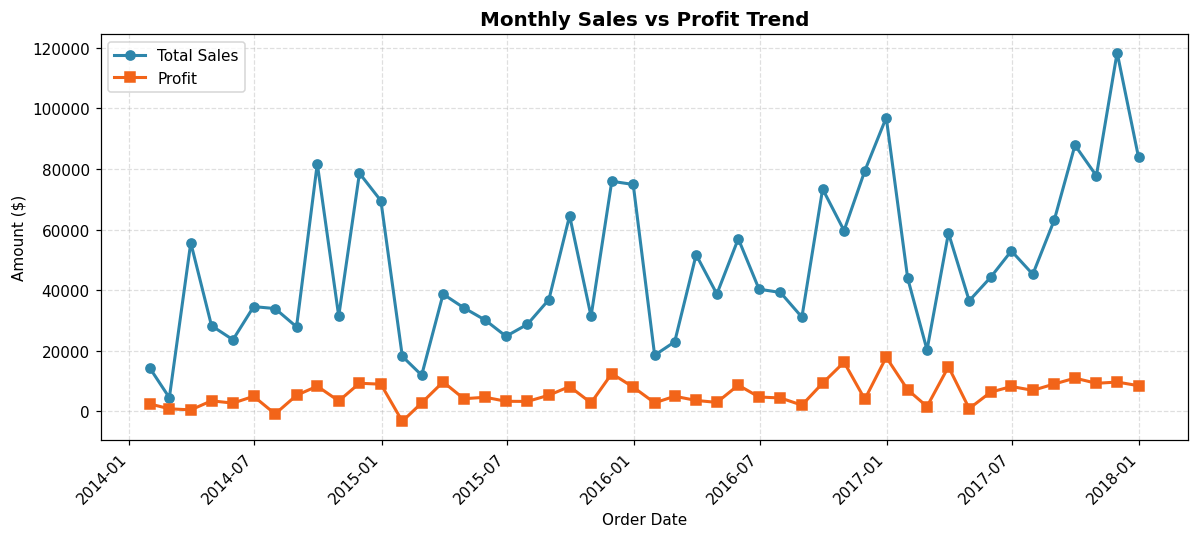

In [ ]:
# sales trend over time
monthly_trend = df.groupby(pd.Grouper(key="Order Date", freq="ME"))[["Sales", "Profit"]].sum().reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly_trend["Order Date"], monthly_trend["Sales"],
        color=PALETTE[0], linewidth=2, marker="o", label="Total Sales")
ax.plot(monthly_trend["Order Date"], monthly_trend["Profit"],
        color=PALETTE[1], linewidth=2, marker="s", label="Profit")

ax.set_title("Monthly Sales vs Profit Trend", fontsize=13, fontweight="bold")
ax.set_xlabel("Order Date")
ax.set_ylabel("Amount ($)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend()
plt.xticks(rotation=45, ha="right")
fig.tight_layout()

# 保存图片
fig.savefig("01_monthly_sales_profit_trend.png", dpi=150, bbox_inches="tight")
print("Figure saved: monthly_sales_profit_trend.png")

plt.show()


In [ ]:
# category analysis
sales_by_category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
profit_by_category = df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
sales_by_subcat = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)
profit_by_subcat = df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False)

print("\nSales by Category: \n", sales_by_category)
print("\nProfit by Category: \n", profit_by_category)
print("\nSales by Sub-Category: \n",sales_by_subcat)
print("\nProfit by Sub-Category: \n", profit_by_subcat)

worst_subcats = profit_by_subcat[profit_by_subcat < 0]

insight(f"Top category by sales is '{sales_by_category.index[0]}' "
        f"(${sales_by_category.iloc[0]:,.0f}), but top category by PROFIT is "
        f"'{profit_by_category.index[0]}' — sales volume doesn't always mean the most profit.")
if len(worst_subcats) > 0:
    insight(f"Sub-categories operating at a LOSS: {', '.join(worst_subcats.index)} — "
            f"these need pricing or discount-policy review.")

Figure saved: 02_sales_by_category.png


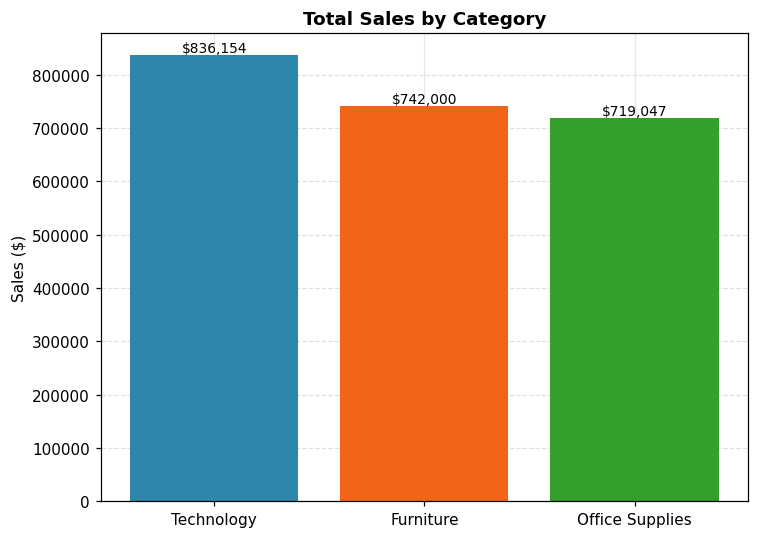

In [74]:
# Bar chart: Sales by Category
fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(sales_by_category.index, sales_by_category.values,
       color=PALETTE[:len(sales_by_category)])
ax.set_title("Total Sales by Category", fontweight="bold")
ax.set_ylabel("Sales ($)")
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for i, v in enumerate(sales_by_category.values):
    ax.text(i, v, f"${v:,.0f}", ha="center", va="bottom", fontsize=9)

fig.tight_layout()
save_path = "02_sales_by_category.png"
fig.savefig(save_path, dpi=150, bbox_inches="tight")
print(f"Figure saved: {save_path}")
plt.show()


Figure saved: 03_profit_by_subcategory.png


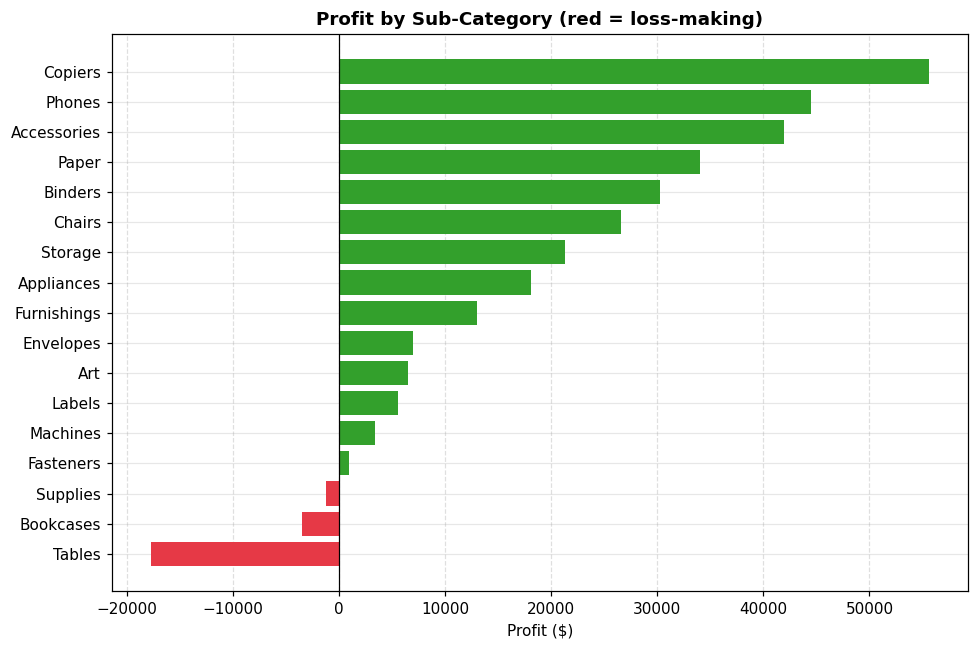

In [76]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = [PALETTE[2] if v >= 0 else PALETTE[3] for v in profit_by_subcat.values]
ax.barh(profit_by_subcat.index[::-1], profit_by_subcat.values[::-1],
        color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Profit by Sub-Category (red = loss-making)", fontweight="bold")
ax.set_xlabel("Profit ($)")
ax.grid(True, axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

fig.tight_layout()
save_path = "03_profit_by_subcategory.png"
fig.savefig(save_path, dpi=150, bbox_inches="tight")
print(f"Figure saved: {save_path}")
plt.show()

Figure saved: 04_sales_share_by_category.png


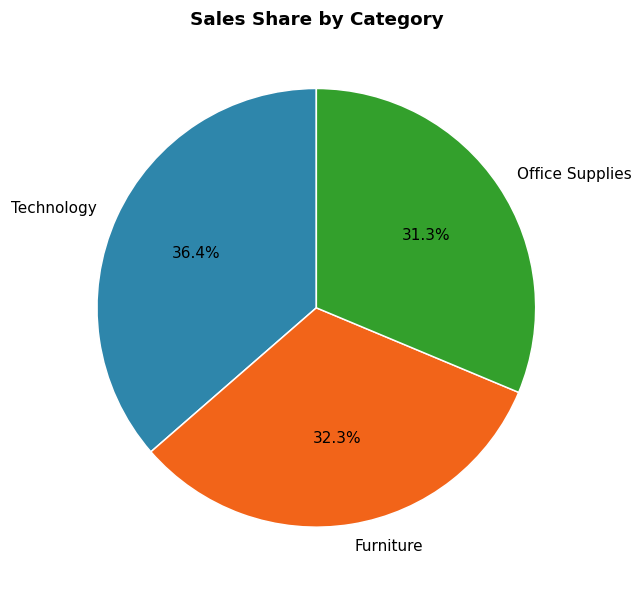

In [77]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    sales_by_category.values,
    labels=sales_by_category.index,
    autopct="%1.1f%%",
    colors=PALETTE[:len(sales_by_category)],
    startangle=90,
    wedgeprops={"edgecolor": "white"},
)
ax.set_title("Sales Share by Category", fontweight="bold")

fig.tight_layout()
save_path = "04_sales_share_by_category.png"
fig.savefig(save_path, dpi=150, bbox_inches="tight")
print(f"Figure saved: {save_path}")
plt.show()

In [ ]:
# regional analysis
sales_by_region = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
profit_by_region = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
sales_by_state = df.groupby("State")["Sales"].sum().sort_values(ascending=False)
profit_by_state = df.groupby("State")["Profit"].sum().sort_values(ascending=False)

print("\nSales by Region:\n", sales_by_region)
print("\nProfit by Region:\n", profit_by_region)

top5_states = profit_by_state.head(5)
bottom5_states = profit_by_state.tail(5)
print("\nTop 5 States by Profit:\n", top5_states)
print("\nBottom 5 States by Profit:\n", bottom5_states)

insight(f"'{profit_by_region.index[0]}' is the most profitable region "
        f"(${profit_by_region.iloc[0]:,.0f}), while '{profit_by_region.index[-1]}' "
        f"lags behind (${profit_by_region.iloc[-1]:,.0f}) — worth investigating regional pricing/logistics costs.")
if bottom5_states.iloc[0] < 0:
    insight(f"'{bottom5_states.index[0]}' is the weakest state, losing "
            f"${abs(bottom5_states.iloc[0]):,.0f} overall — consider reviewing product mix or discount levels there.")


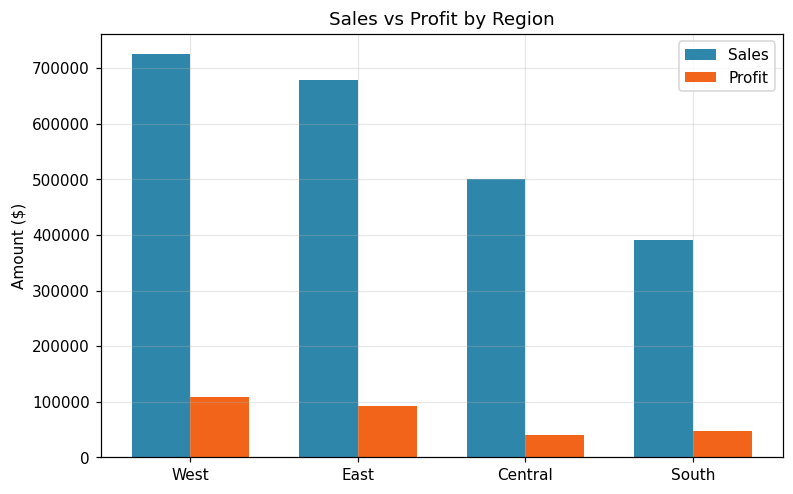

In [71]:
# Bar chart: Sales & Profit by Region
fig, ax = plt.subplots(figsize = (8, 5))
x = np.arange(len(sales_by_region))
width = 0.35
ax.bar(x - width/2, sales_by_region.values, width, label="Sales",color=PALETTE[0])
ax.bar(x + width/2, profit_by_region.reindex(sales_by_region.index).values, width, label="Profit",color=PALETTE[1])
ax.set_xticks(x)
ax.set_xticklabels(sales_by_region.index)
ax.set_title("Sales vs Profit by Region")
ax.set_ylabel("Amount ($)")
ax.legend()
